# Spots F and C: integral against pulse height, channel by channel (-82 V, DCRC1pB trigger)

*Eleventh notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01. (It was `spot-f-integral-vs-height.ipynb` before spot C was added.)*

The other way round from `integral-vs-height.ipynb`, where bands of Side2pF were cut in the plane of integral and height and then placed on the face: here the events are first cut on their **position**, a tight circle around each of the two high-activity spots in the plane of the 20 % delays, and then drawn in the plane of integral and height for all six channels:

* **spot F**, over the centre disc: within `TIGHT_F` = 0.5 us of its centre (about 95 % spot events; see `spot-f-tight-energy.ipynb`);
* **spot C**, over the sector C: within `TIGHT_C` = 0.5 us of its centre (also about 95 %, estimated the same way from the ring around it).

For comparison, the events outside both spots (farther than 2.25 us from either centre), with the same selection. The selection is that of the position notebooks (`spots_82v.load()`): real triggers, the sum of the positive offset-subtracted integrals above 2, all six 20 % times present and within 60 us of each other. The height is `current_max` of `peak` (ADC counts above the baseline, `amps_per_adc` = 1), the integral that of `integral` (ADC counts x s); both use the baseline of samples 10 to 500.

**The lines on the plots.** Red dotted: each channel's saturated height (the 99.99th percentile of the height of all real triggers) and the largest integral it allows (that height times the 2.88 ms from the trigger to the end of the trace). Dashed: the three bands found in Side2pF in `integral-vs-height.ipynb`, as lines of constant `integral / height` through the origin: the 0.8 ms band (on Side2pF along its drifting ridge, `0.78 + (800 - h) x 1.8e-4` ms, and as a constant 0.8 ms on the other channels), 2.55 ms and 2.7 ms. The bands were found in Side2pF only; on the other channels the lines are a reference for the same pulse length, not a band of those channels.

Needs `goldpan` and the output of `r76-82v-dcrc1pb.dataset.toml` in `~/goldsluice-output/r76-82v-dcrc1pb`. Run with the `darkmatter_cli_env` kernel.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors

from goldpan.adapters import parquet
from spots_82v import LETTERS, OUT, SPOTS, TIGHT_C, TIGHT_F, in_spot, load

d = load()
q = parquet.read(OUT, detector="NAI-S2").quantities
I = {k: d["integral"][:, n] for n, k in enumerate(LETTERS)}
H = {k: np.asarray(q[f"Side2p{k}"]["current_max"], dtype=float) for k in LETTERS}
real = d["trigger"] == "Unknown"
T_AFTER = (4096 - 500) * 0.8e-6
H_SAT = {k: np.percentile(H[k][real], 99.99) for k in LETTERS}

def tight(name, radius):
    x0, y0, _ = SPOTS[name]
    return d["use"] & (np.hypot(d["xdel"] - x0, d["ydel"] - y0) < radius)

sel = {"spot F": tight("F", TIGHT_F), "spot C": tight("C", TIGHT_C)}
sel["outside both spots"] = d["use"] & ~in_spot(d["xdel"], d["ydel"], "C", scale=1.5) & ~in_spot(d["xdel"], d["ydel"], "F", scale=1.5)
print("; ".join(f"{name}: {m.sum():,} events" for name, m in sel.items()))
print(f"{'':34}" + "".join(f"{'Side2p' + k:>10}" for k in LETTERS))
for what, f in (("median height", lambda m, k: f"{np.median(H[k][m]):>10.0f}"),
                ("median integral", lambda m, k: f"{np.median(I[k][m]):>10.2f}"),
                ("median integral/height (ms)", lambda m, k: f"{np.median(I[k][m & (H[k] > 50)] / H[k][m & (H[k] > 50)]) * 1e3:>10.2f}")):
    for name, m in sel.items():
        print(f"{name + ': ' + what:34}" + "".join(f(m, k) for k in LETTERS))

spot F: 15,792 events; spot C: 15,567 events; outside both spots: 313,494 events
                                     Side2pA   Side2pB   Side2pC   Side2pD   Side2pE   Side2pF
spot F: median height                   1082       891       410       738       486       660
spot C: median height                   1109       899       418       744       495       676
outside both spots: median height       1096       901       417       739       497       676
spot F: median integral                 2.50      2.21      1.05      1.88      1.24      1.71
spot C: median integral                 2.40      2.14      1.05      1.85      1.24      1.70


outside both spots: median integral      1.72      1.53      0.78      1.35      0.96      1.23
spot F: median integral/height (ms)      2.40      2.57      2.59      2.58      2.61      2.65
spot C: median integral/height (ms)      2.20      2.43      2.54      2.51      2.53      2.56


outside both spots: median integral/height (ms)      1.69      1.88      2.09      2.04      2.17      2.05


## Integral against height

One figure of six panels for each selection, on the same axes as in `integral-vs-height.ipynb`, with the band lines.

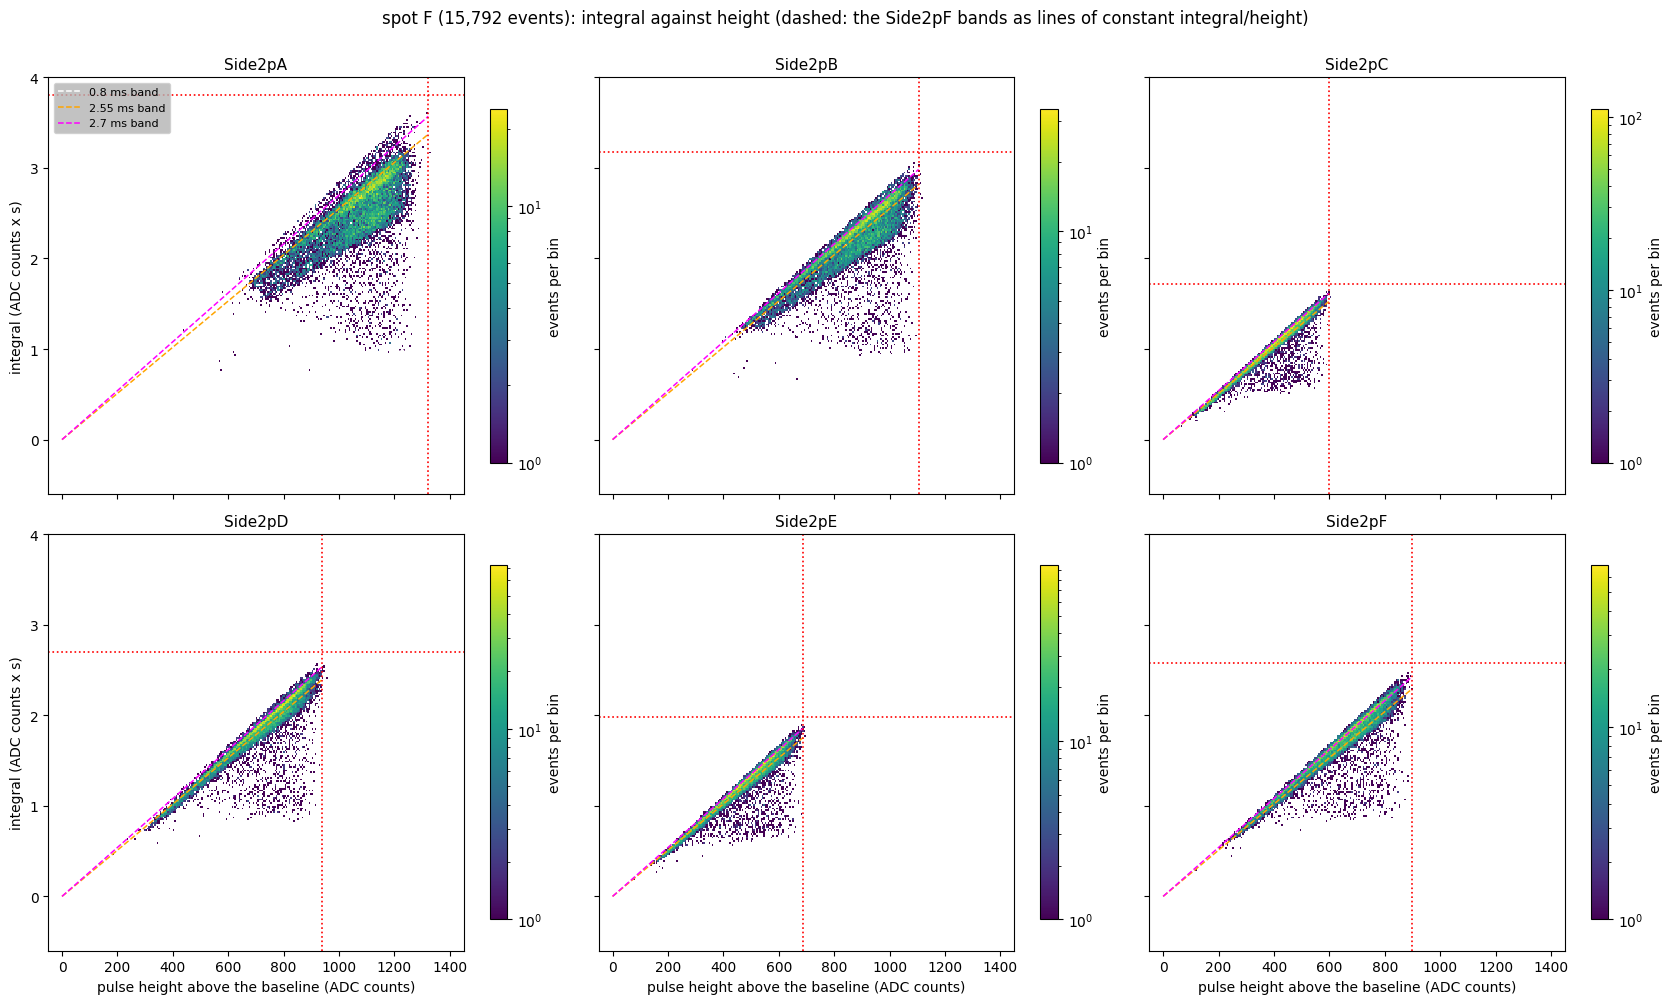

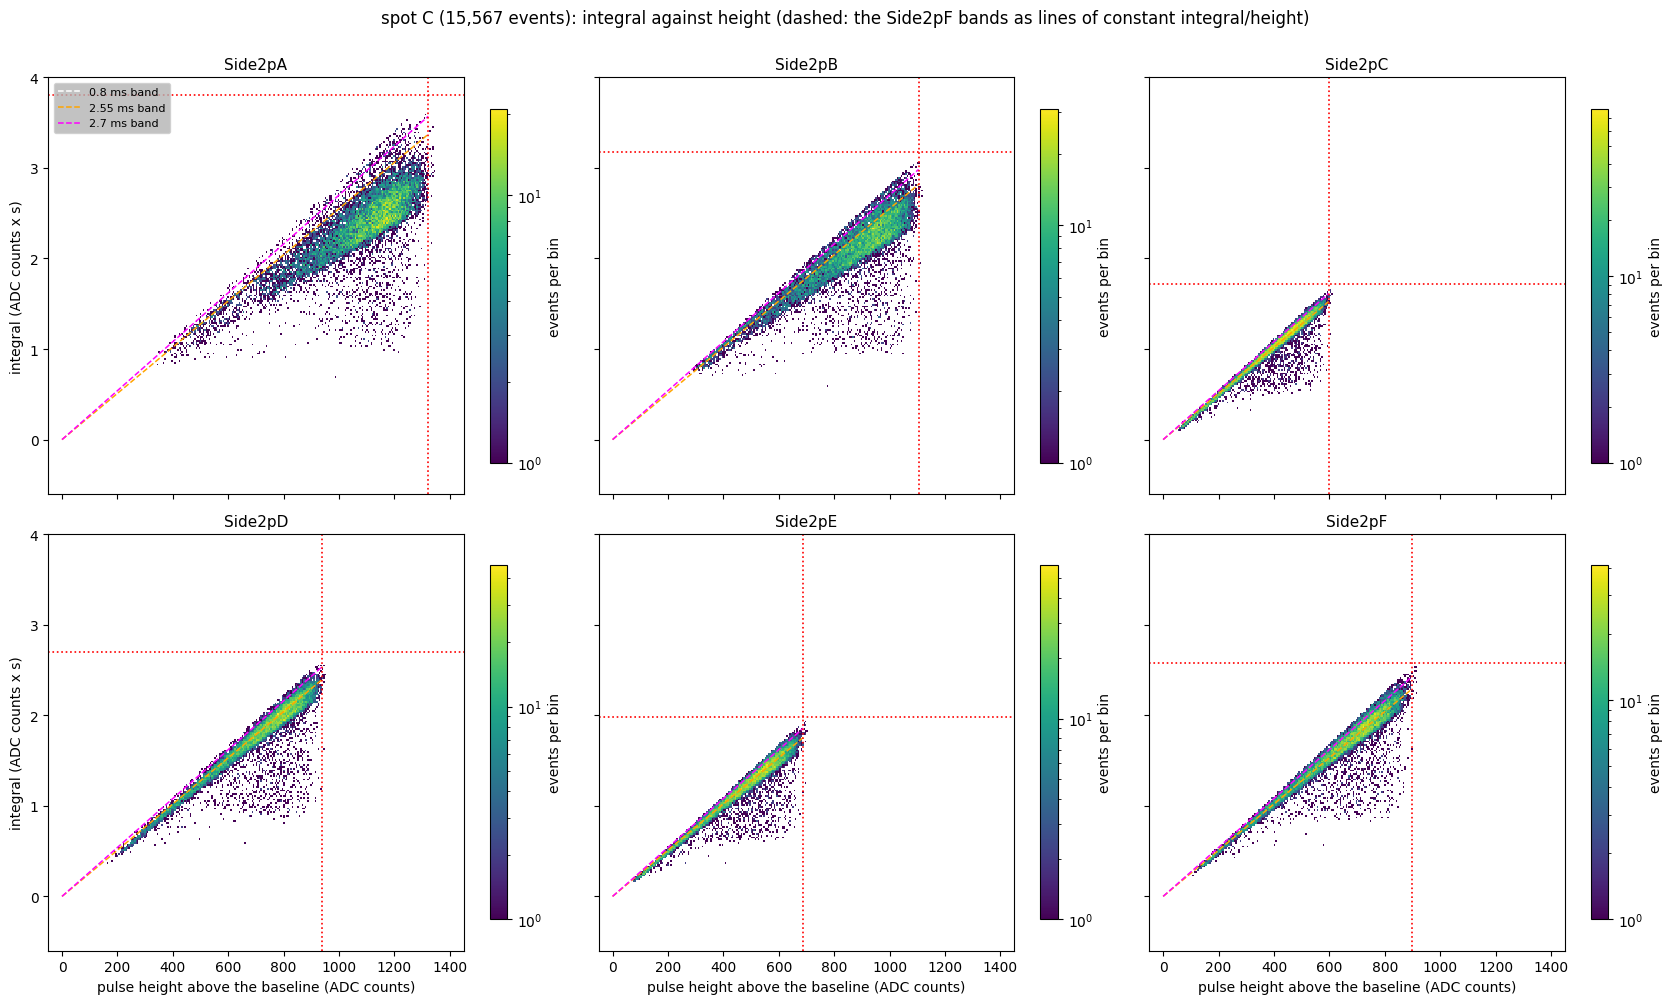

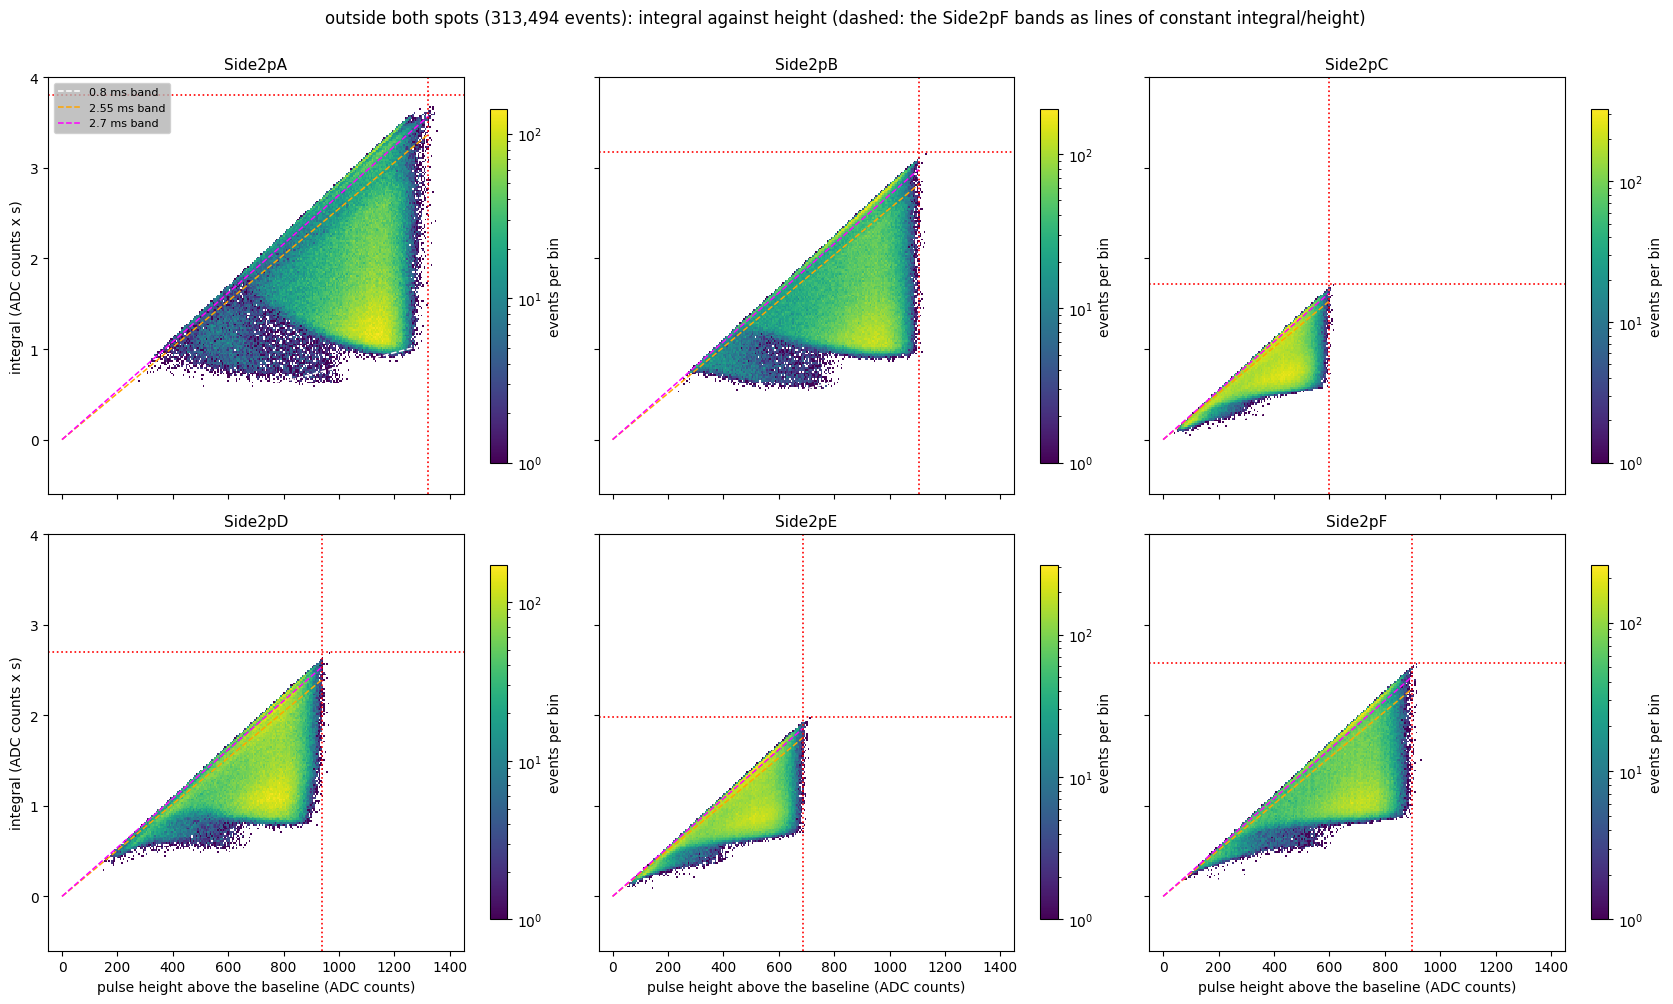

In [2]:
HR, IR = (-50, 1450), (-0.6, 4.0)
BANDS = {"0.8 ms": ("w", "--"), "2.55 ms": ("orange", "--"), "2.7 ms": ("magenta", "--")}

def band_ratio(name, k, h):
    """integral/height (ms) of the band `name` at height h; the 0.8 ms band drifts on Side2pF (integral-vs-height.ipynb)."""
    if name == "0.8 ms":
        return 0.78 + (800 - h) * 1.8e-4 if k == "F" else np.full_like(h, 0.8)
    return np.full_like(h, float(name.split()[0]))

def overlay(ax, k):
    hs = np.linspace(0, H_SAT[k], 100)
    for name, (c, ls) in BANDS.items():
        ax.plot(hs, hs * band_ratio(name, k, hs) * 1e-3, color=c, linestyle=ls, linewidth=1.1, label=f"{name} band")
    ax.axvline(H_SAT[k], color="r", linestyle=":", linewidth=1.2)
    ax.axhline(H_SAT[k] * T_AFTER, color="r", linestyle=":", linewidth=1.2)

def six_panels(m, title):
    fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
    for ax, k in zip(axes.flat, LETTERS):
        h = ax.hist2d(H[k][m], I[k][m], bins=[290, 230], range=[HR, IR], cmap="viridis", norm=colors.LogNorm(), cmin=1)
        overlay(ax, k)
        ax.set_xlim(*HR)
        ax.set_ylim(*IR)
        ax.set_title(f"Side2p{k}", fontsize=11)
        fig.colorbar(h[3], ax=ax, shrink=0.85, label="events per bin")
    for ax in axes[-1]:
        ax.set_xlabel("pulse height above the baseline (ADC counts)")
    for ax in axes[:, 0]:
        ax.set_ylabel("integral (ADC counts x s)")
    axes[0, 0].legend(loc="upper left", fontsize=8, facecolor="0.7")
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    plt.show()

for name, m in sel.items():
    six_panels(m, f"{name} ({m.sum():,} events): integral against height (dashed: the Side2pF bands as lines of constant integral/height)")

## Effective pulse length

`integral / height` (ms) of each channel for the three selections, each normalised to its number of events, for heights above 50 counts, with the band values marked (dashed; the 0.8 ms band of Side2pF drifts from 0.78 to 0.91 ms over its heights, shaded) and 2.88 ms, a pulse held to the end of the trace (red dotted).

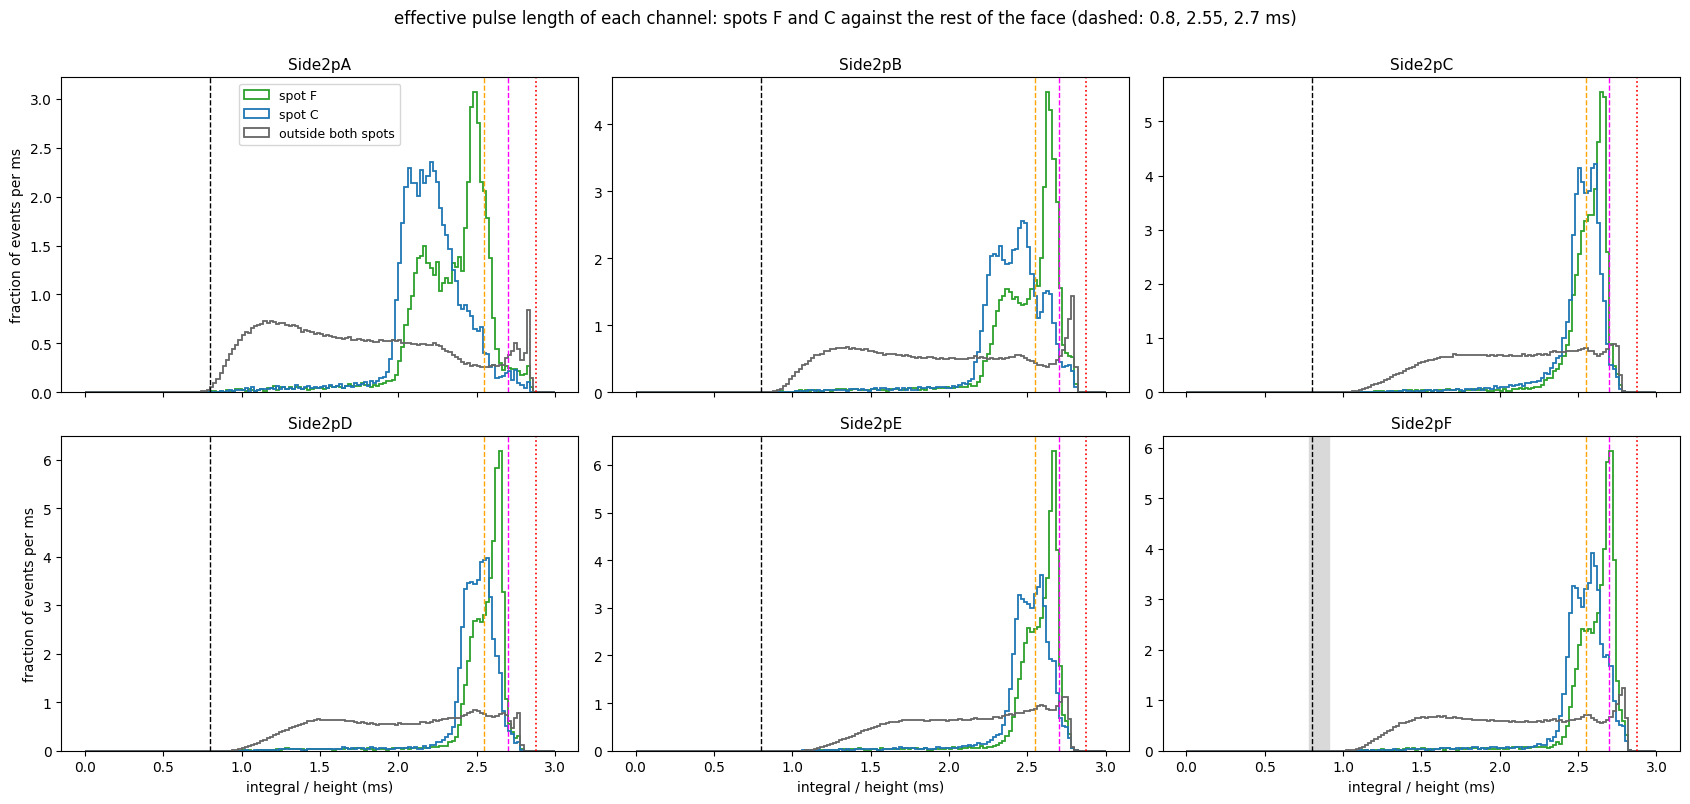

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
bins = np.linspace(0, 3, 151)
for ax, k in zip(axes.flat, LETTERS):
    for (name, m), c in zip(sel.items(), ("C2", "C0", "0.4")):
        mm = m & (H[k] > 50)
        ax.hist(I[k][mm] / H[k][mm] * 1e3, bins=bins, histtype="step", density=True, color=c, linewidth=1.3, label=name)
    if k == "F":
        ax.axvspan(0.78, 0.91, color="0.85", zorder=0)
    for name, (c, ls) in BANDS.items():
        ax.axvline(0.8 if name == "0.8 ms" else float(name.split()[0]), color="k" if c == "w" else c, linestyle=ls, linewidth=1.0)
    ax.axvline(T_AFTER * 1e3, color="r", linestyle=":", linewidth=1.2)
    ax.set_title(f"Side2p{k}", fontsize=11)
for ax in axes[-1]:
    ax.set_xlabel("integral / height (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("fraction of events per ms")
axes[0, 0].legend(fontsize=9)
fig.suptitle("effective pulse length of each channel: spots F and C against the rest of the face (dashed: 0.8, 2.55, 2.7 ms)", y=1.0)
fig.tight_layout()
plt.show()

## Are the spot pulses saturated? Traces from the bulk of the energy spectra

Random events of each spot whose energy (the sum of the six integrals, as in `spots-82v-energy.ipynb`) lies in the **bulk** of that spot's spectrum, between its 25th and 75th percentiles, drawn in all channels in the tiled layout of the earlier notes (one row per readout board, one column per board input), baseline subtracted with the baseline of `integral` (grey band). The **red dashed line in each tile is that channel's saturated height** (the 99.99th percentile of its height over all real triggers): a saturated pulse runs flat along it.

A flat top alone does not prove saturation, since a pulse can also be long. The table under each figure gives, for each channel, the height as a fraction of the saturated height and the **flat-top time**: how long the trace stays within 2 % of its own maximum (after smoothing over 25 samples, 20 us). A pulse that is not saturated has a rounded peak and a short flat-top time (tens of us); a saturated one sits at the saturated height for hundreds of us or more.

In [4]:
from pathlib import Path

import goldpan.channels as pch
from goldpan.adapters import idx
from goldpan.config import DCRC_RUN76

RAW = Path.home() / "idx"
N_BULK, SEED_BULK = 4, 3
E = d["integral"].sum(axis=1)
g, p = DCRC_RUN76.glitch_samples, DCRC_RUN76.pretrigger_samples
t_us = (np.arange(4096) - p) * DCRC_RUN76.sample_period_s * 1e6
SENSORS = {c.name: (c.detector, c.channel) for c in pch.sensor_channels()}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]
INFO = {key: pch.channel_info(*key) for key in KEYS}
BOARD_COLOUR = {"DCRC1": "C0", "DCRC3": "C1"}

rng = np.random.default_rng(SEED_BULK)
bulk = {}
for name in ("spot F", "spot C"):
    m = sel[name]
    lo, hi = np.percentile(E[m], [25, 75])
    bulk[name] = np.sort(rng.choice(np.flatnonzero(m & (E >= lo) & (E <= hi)), N_BULK, replace=False))
    print(f"{name}: energy bulk (25-75 %) {lo:.2f} to {hi:.2f}; chosen: " + ", ".join(f"{d['series'][i]} {d['dump'][i]} ev {d['event'][i]} (E {E[i]:.2f})" for i in bulk[name]))

traces = {}
chosen_all = np.concatenate(list(bulk.values()))
for s, dmp in sorted({(d["series"][i], d["dump"][i]) for i in chosen_all}):
    ev = idx.read(RAW / (dmp if dmp.startswith(s) else f"{s}_{dmp}"), detector_name="NAI-S2", channels=SENSORS, config=DCRC_RUN76)
    numbers = np.asarray(ev.quantities["event"])
    segment = {nm: seg for (nm, seg) in ev.traces}
    for i in chosen_all:
        if (d["series"][i], d["dump"][i]) == (s, dmp):
            j = int(np.flatnonzero(numbers == d["event"][i])[0])
            traces[i] = {}
            for nm in SENSORS:
                x = np.asarray(ev.traces[(nm, segment[nm])][j], dtype=float)
                traces[i][nm] = x - x[g:p].mean()
worst = max(abs(traces[i][f"Side2p{k}"].sum() * DCRC_RUN76.sample_period_s - I[k][i]) for i in chosen_all for k in LETTERS)
print(f"largest difference between the recomputed and the processed integrals: {worst:.1e}")

def flat_top_us(x, frac=0.02, smooth=25):
    """How long (us) the smoothed trace stays within `frac` of its maximum, counting every sample after the trigger."""
    s = np.convolve(x, np.ones(smooth) / smooth, mode="same")[p:]
    return (s >= (1 - frac) * s.max()).sum() * DCRC_RUN76.sample_period_s * 1e6

C:\Users\Anthony\AppData\Local\Temp\ipykernel_22052\3946893457.py:12: UserWarning: sensor_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  SENSORS = {c.name: (c.detector, c.channel) for c in pch.sensor_channels()}
C:\Users\Anthony\AppData\Local\Temp\ipykernel_22052\3946893457.py:14: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  INFO = {key: pch.channel_info(*key) for key in KEYS}


spot F: energy bulk (25-75 %) 8.90 to 11.88; chosen: 07221111_2153 F0046 ev 12024 (E 9.78), 07221112_0943 F0009 ev 13025 (E 10.76), 07221112_0943 F0019 ev 13341 (E 9.17), 07221112_2249 F0040 ev 13217 (E 10.09)
spot C: energy bulk (25-75 %) 8.57 to 11.60; chosen: 07221111_2153 F0006 ev 10400 (E 9.52), 07221111_2153 F0012 ev 11287 (E 10.75), 07221112_2249 F0003 ev 12773 (E 10.14), 07221114_2141 F0024 ev 10550 (E 9.50)


largest difference between the recomputed and the processed integrals: 2.4e-13


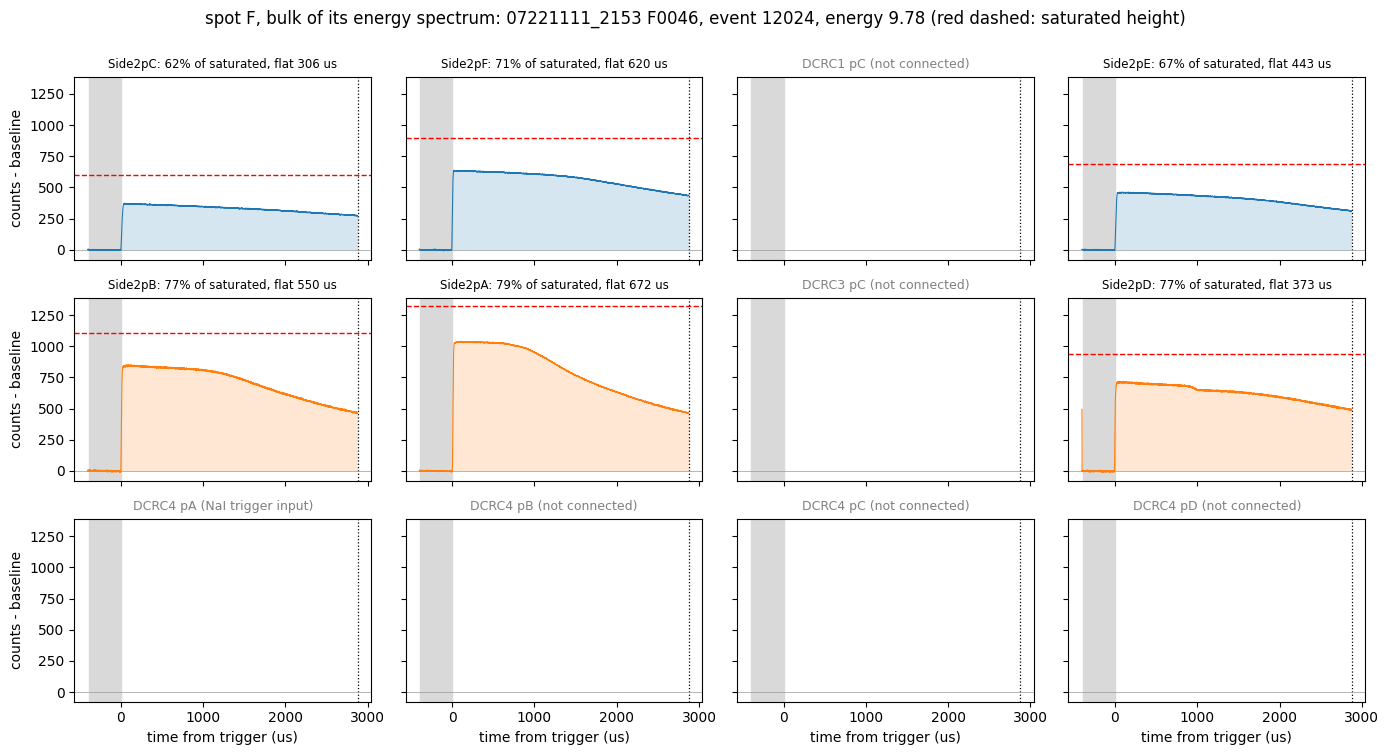

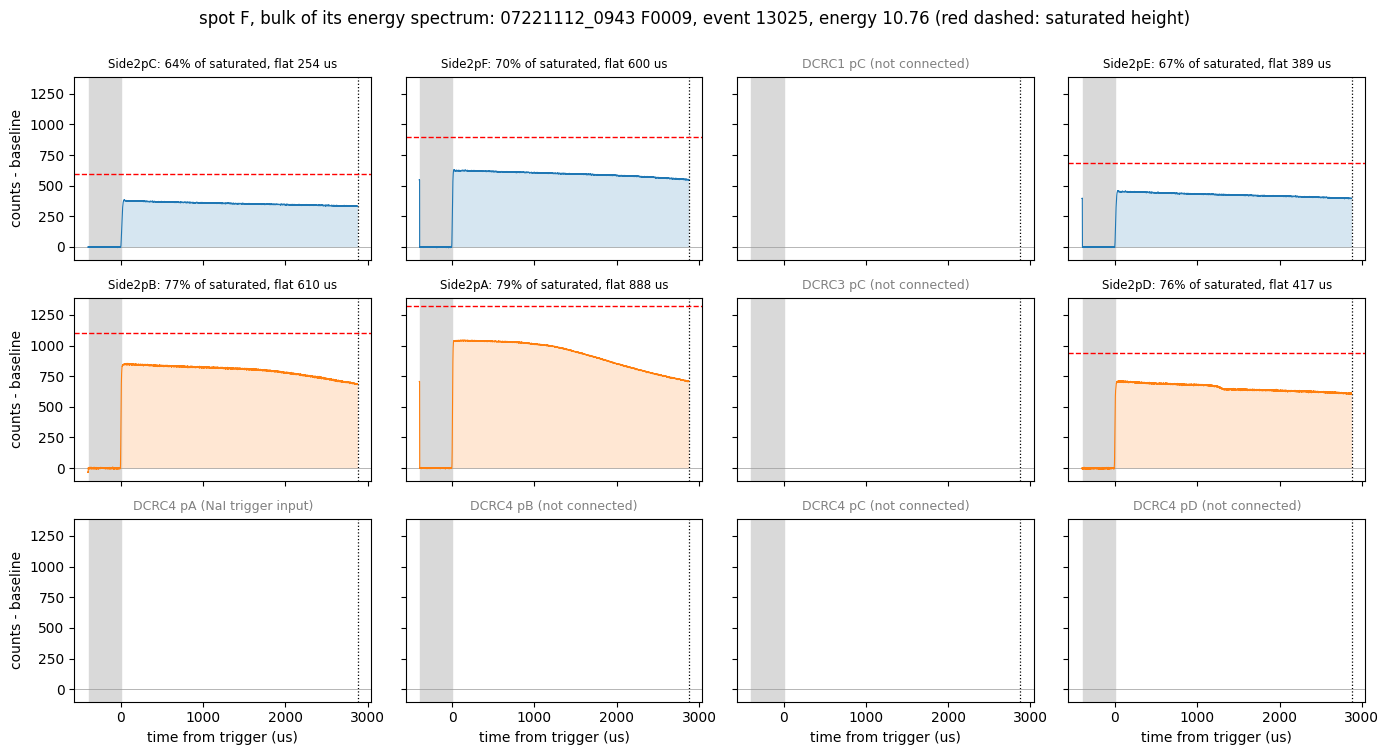

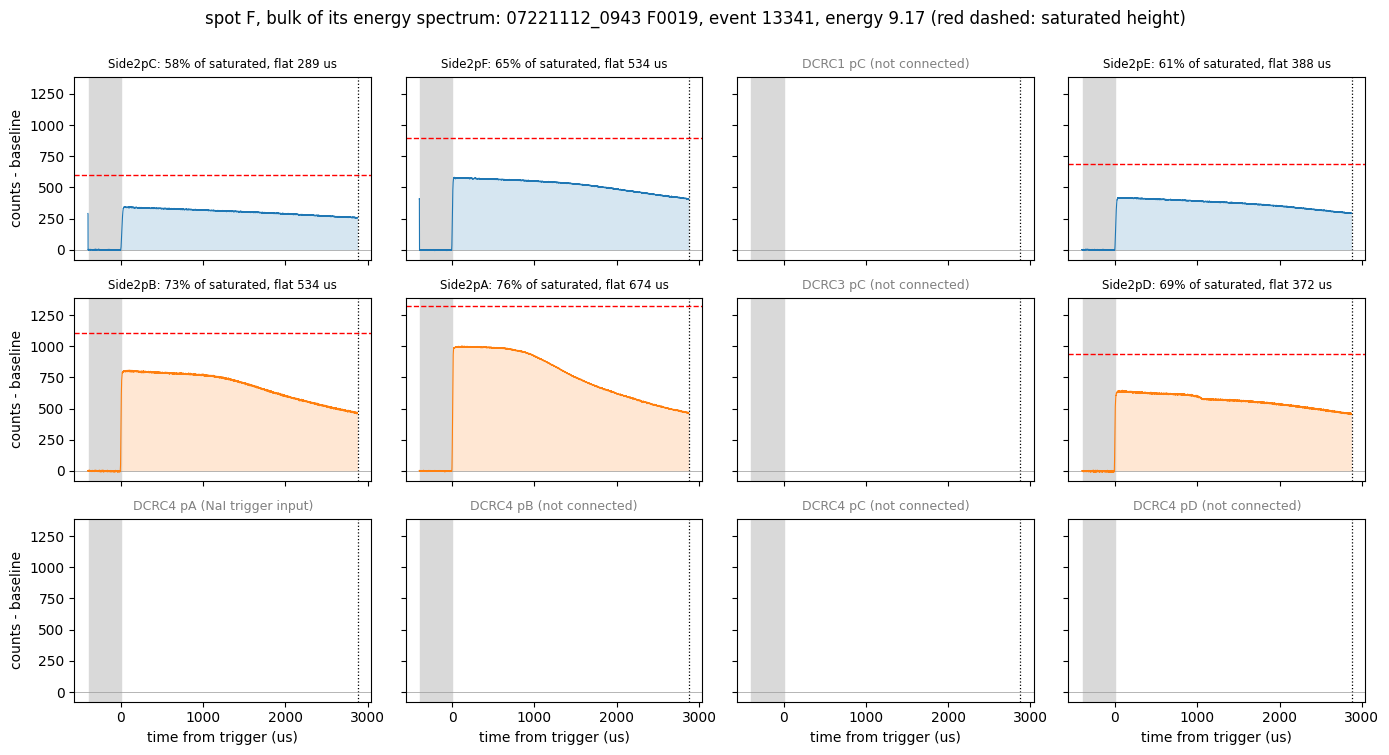

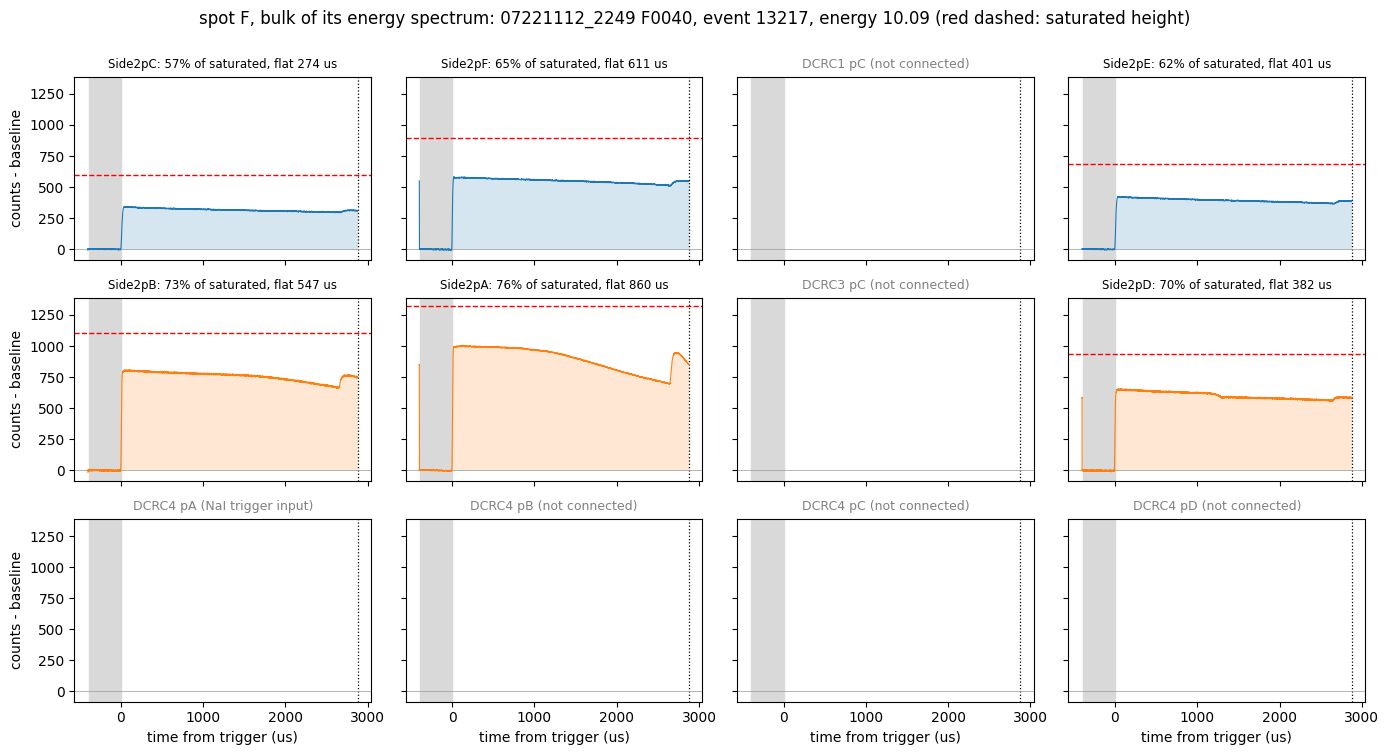

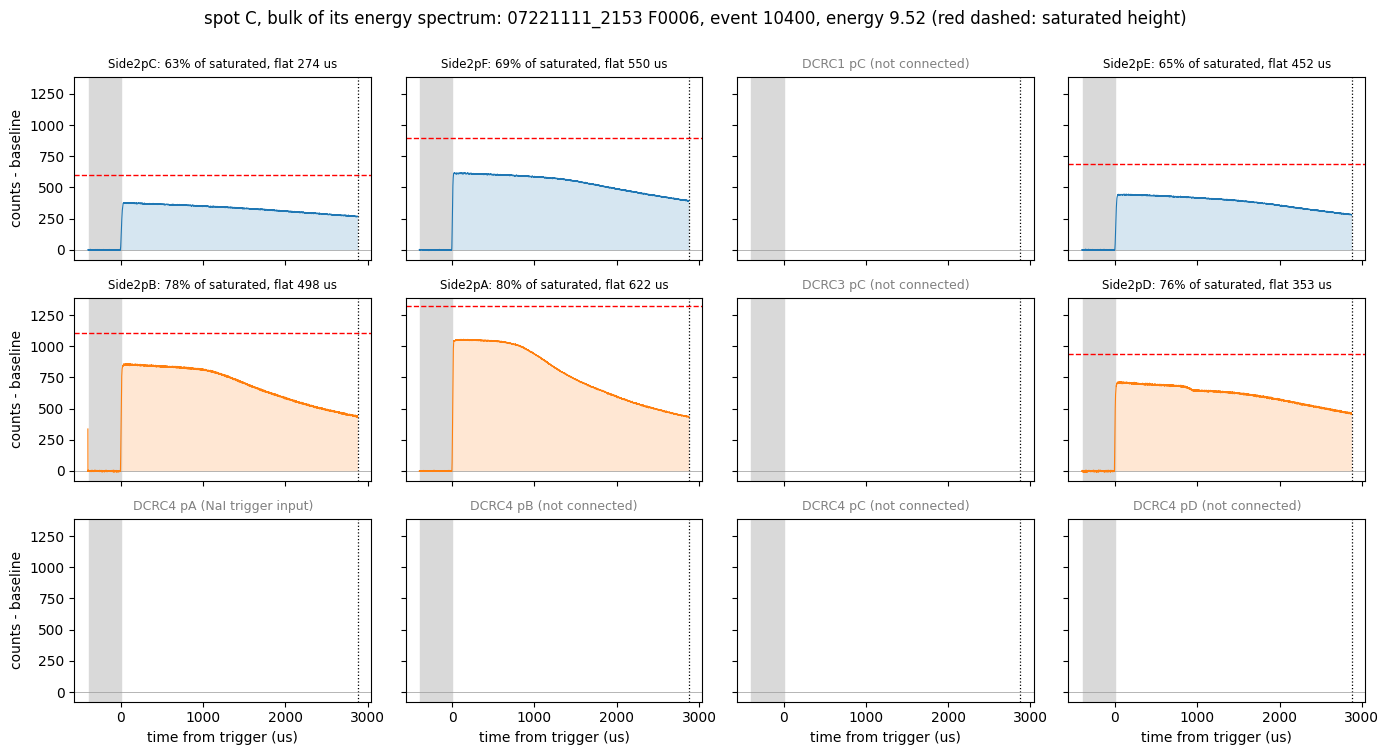

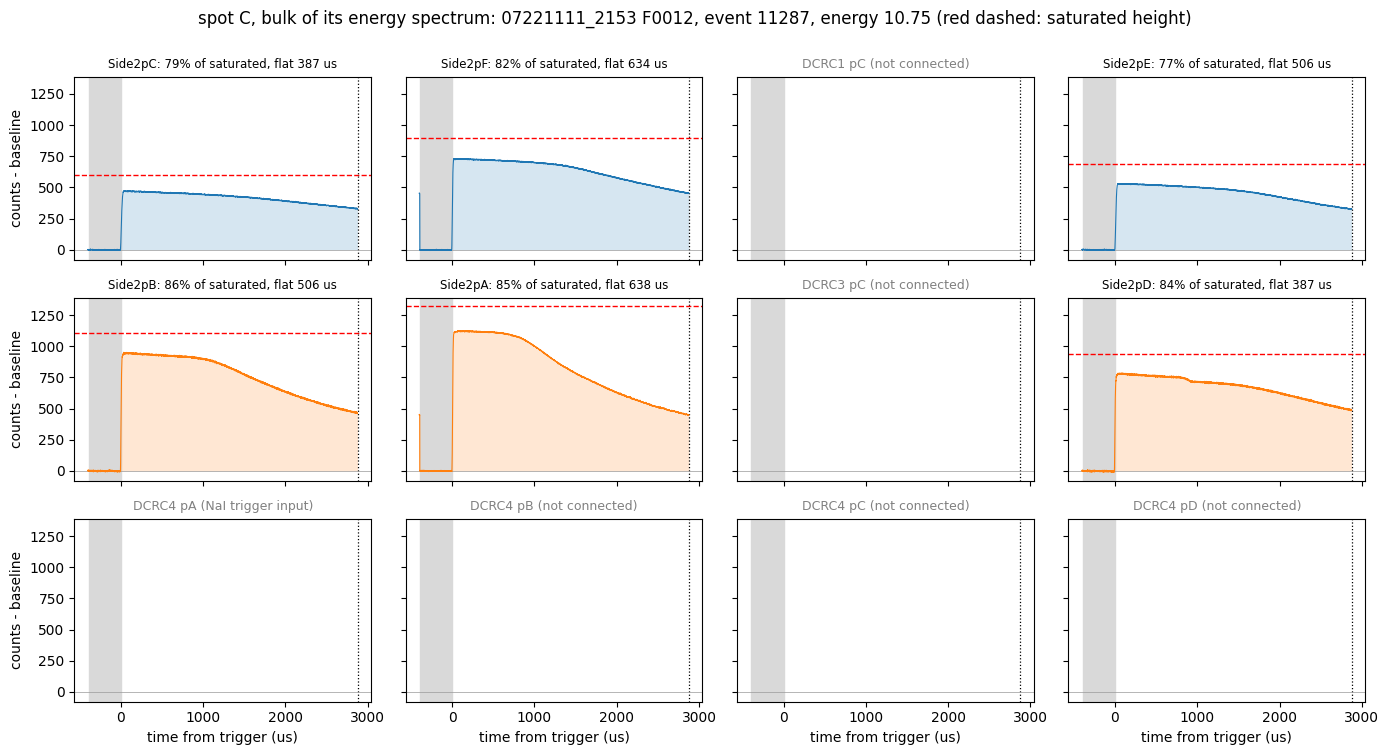

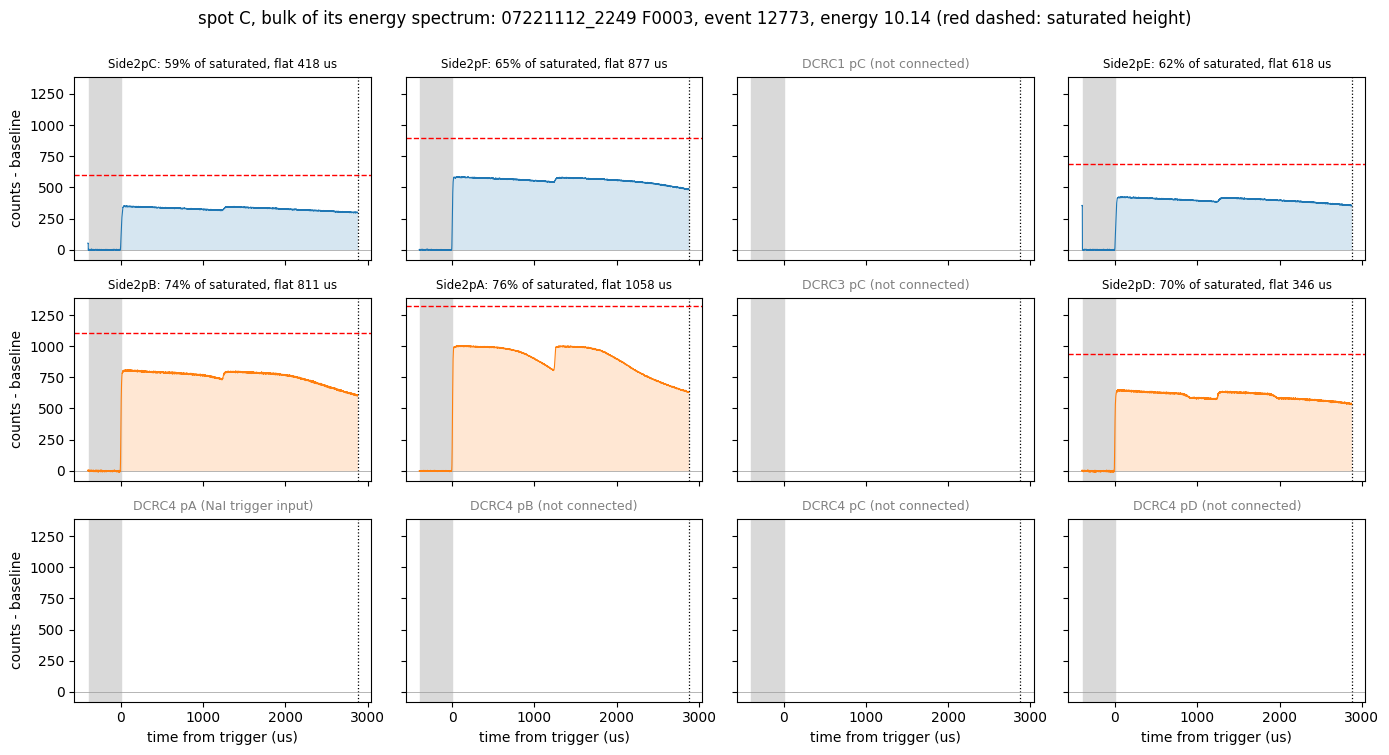

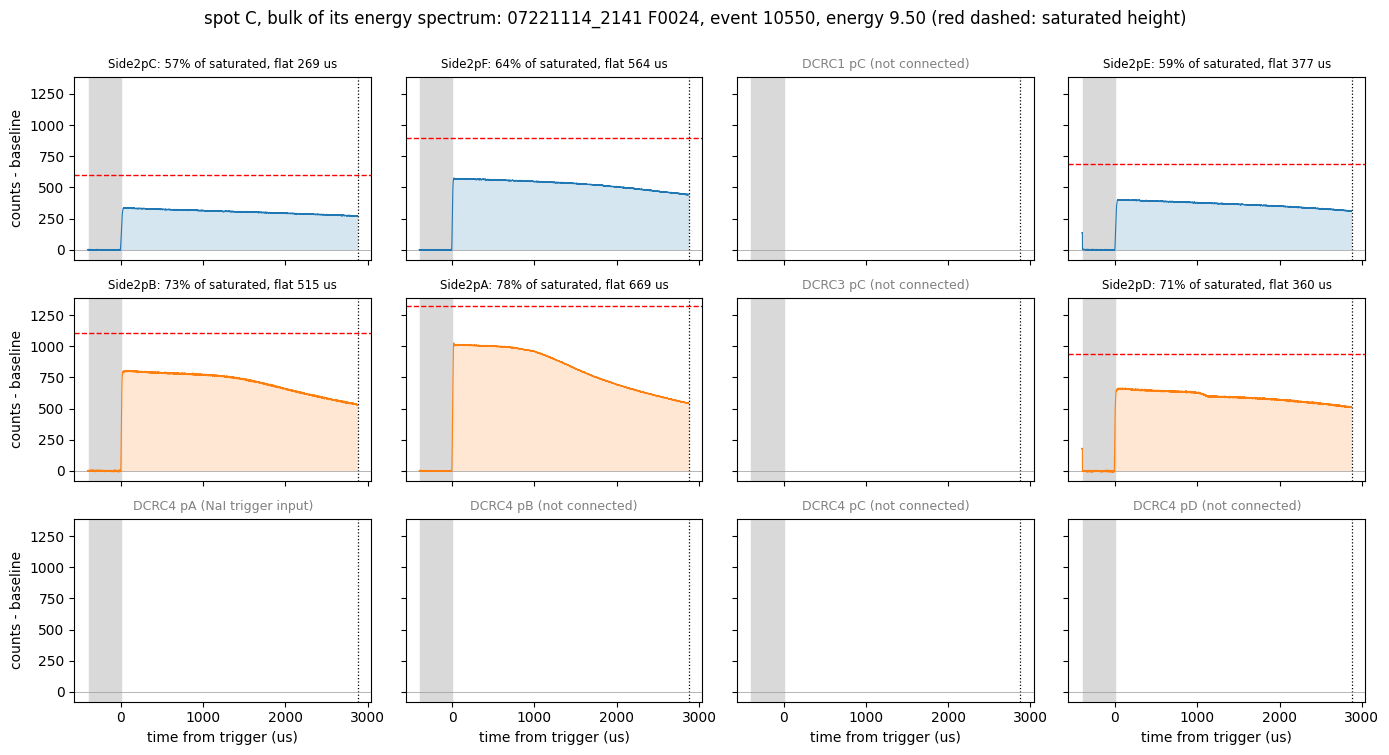

In [5]:
for name in ("spot F", "spot C"):
    for i in bulk[name]:
        tr = traces[i]
        lo = min(f.min() for f in tr.values())
        hi = max(max(f.max() for f in tr.values()), max(H_SAT.values()))
        pad = 0.05 * (hi - lo)
        fig, axes = plt.subplots(3, 4, figsize=(14, 7.5), sharex=True, sharey=True)
        for key, ax in zip(KEYS, axes.flat):
            c = INFO[key]
            ax.axvspan(t_us[g], 0, color="0.85", zorder=0)
            ax.axvline(t_us[-1], color="k", linestyle=":", linewidth=0.9)
            ax.axhline(0, color="0.6", linewidth=0.5)
            if c.role != pch.SENSOR:
                what = "NaI trigger input" if c.role == pch.NAI_TRIGGER else "not connected"
                ax.set_title(f"{c.dcrc} {c.board_input} ({what})", fontsize=9, color="0.5")
                continue
            k = c.name[-1]
            ax.axhline(H_SAT[k], color="r", linestyle="--", linewidth=1.0)
            ax.fill_between(t_us, tr[c.name], 0, color=BOARD_COLOUR[c.dcrc], alpha=0.18, linewidth=0)
            ax.plot(t_us, tr[c.name], linewidth=0.8, color=BOARD_COLOUR[c.dcrc])
            ax.set_title(f"{c.name}: {H[k][i] / H_SAT[k]:.0%} of saturated, flat {flat_top_us(tr[c.name]):.0f} us", fontsize=8.5)
        for ax in axes[-1]:
            ax.set_xlabel("time from trigger (us)")
        for ax in axes[:, 0]:
            ax.set_ylabel("counts - baseline")
        axes[0, 0].set_ylim(lo - pad, hi + pad)
        fig.suptitle(f"{name}, bulk of its energy spectrum: {d['series'][i]} {d['dump'][i]}, event {d['event'][i]}, energy {E[i]:.2f} "
                     f"(red dashed: saturated height)", y=1.0)
        fig.tight_layout()
        plt.show()

### Summary over the chosen events

Height as a fraction of the saturated height, and flat-top time, for every chosen event and channel.

In [6]:
print(f"{'event':>40}" + "".join(f"{'Side2p' + k:>16}" for k in LETTERS))
for name in ("spot F", "spot C"):
    for i in bulk[name]:
        print(f"{name + ' ' + str(d['event'][i]) + f' (E {E[i]:.1f})':>40}" +
              "".join(f"{H[k][i] / H_SAT[k]:>8.0%}{flat_top_us(traces[i][f'Side2p{k}']):>6.0f}us" for k in LETTERS))

                                   event         Side2pA         Side2pB         Side2pC         Side2pD         Side2pE         Side2pF
                    spot F 12024 (E 9.8)     79%   672us     77%   550us     62%   306us     77%   373us     67%   443us     71%   620us
                   spot F 13025 (E 10.8)     79%   888us     77%   610us     64%   254us     76%   417us     67%   389us     70%   600us
                    spot F 13341 (E 9.2)     76%   674us     73%   534us     58%   289us     69%   372us     61%   388us     65%   534us
                   spot F 13217 (E 10.1)     76%   860us     73%   547us     57%   274us     70%   382us     62%   401us     65%   611us
                    spot C 10400 (E 9.5)     80%   622us     78%   498us     63%   274us     76%   353us     65%   452us     69%   550us
                   spot C 11287 (E 10.8)     85%   638us     86%   506us     79%   387us     84%   387us     77%   506us     82%   634us
                   spot C 12773 (E 10.1) 

**Not done.** The spots' own pulse shapes are in `spot-f-tight-traces.ipynb` (spot F only); this notebook only places their events in the plane of integral and height. About 5 % of each tight cut are ordinary events of that place of the face, not subtracted here.